## Le modèle CAPM (Capital Asset Pricing Model)
Le CAPM est une formule mathématique qui établit les rendements espérés d'un actif en fonction du risque systématique.
$$\mathbb{E}(R_i)=R_f+\beta_i(\mathbb{E}(R_m)-R_f)$$
Où $\mathbb{E}(R_i)$ est le rendement attendu du placement, $R_f$ le taux sans risque, $\beta_i$ la mesure du risque systémique lié au marché, $\mathbb{E}(R_m)$ le rendement attendu du marché et finalement $\mathbb{E}(R_m)-R_f$ la prime de risque du marché.<br><br>Simplement, cette formule dit que les rendements d'un placement devraient être égaux à un taux de base sans risque en plus d'une prime en fonction du risque auquel un investisseur s'expose.

In [16]:
import matplotlib.pyplot as plt
import yfinance as yf
import numpy as np
import pandas as pd
from cycler import cycler

BG, PANEL, GRID = "#141518", "#1C1D22", "#2A2C33"
INK, MUTED, ACCENT, GOLD = "#E6E3DC", "#A0A0A8", "#8FA9E6", "#D9B36A"

def set_theme():
    plt.rcParams.update({
        "figure.facecolor": BG, "savefig.facecolor": BG,
        "axes.facecolor": PANEL, "axes.edgecolor": GRID,
        "axes.labelcolor": INK, "axes.titlecolor": INK, "axes.titleweight": "bold",
        "xtick.color": MUTED, "ytick.color": MUTED,
        "text.color": INK, "grid.color": GRID, "axes.grid": True,
        "font.family": "monospace",
        "legend.facecolor": PANEL, "legend.edgecolor": GRID,
        "figure.figsize": (9, 6),
        # couleurs par défaut des séries, dans l'ordre
        "axes.prop_cycle": cycler(color=[ACCENT, GOLD, "#C97B84", "#7FB8A4", MUTED]),
    })

set_theme()

## Le taux sans risque $R_f$
Taux de rendement théorique d'un actif sans risque de perte financière. On se base souvent sur les taux de rendements des obligations du trésor américain. Ces taux sont autour de 3-4% annuels.


In [17]:
DEBUT = "2021-01-01"
FIN = None
TICKER_RF = "^IRX"  # T-bill US 13 semaines


rf = yf.Ticker(TICKER_RF).history(start=DEBUT, end=FIN)["Close"].dropna() / 100
rf.index = rf.index.tz_localize(None)

rf_actuel = rf.iloc[-1]
rf_moyen = rf.mean()


rf_jour = (1 + rf) ** (1 / 252) - 1

print(f"Taux sans risque annuel actuel ({rf.index[-1].date()}) : {rf_actuel:.2%}")
print(f"Taux sans risque annuel moyen depuis {DEBUT} : {rf_moyen:.2%}")
print(f"Équivalent journalier actuel : {rf_jour.iloc[-1]:.5%}")

Taux sans risque annuel actuel (2026-11-06) : 4.00%
Taux sans risque annuel moyen depuis 2021-01-01 : 3.29%
Équivalent journalier actuel : 0.01558%


Le taux actuel (4.00 %) et le taux moyen depuis 2021 (3.29 %) sont assez différents : les taux étaient presque nuls en 2021, puis ont monté rapidement en 2022-2023. Puisque le rendement du marché sera mesuré sur la même période (depuis 2021), on utilisera le **taux moyen** `rf_moyen` pour rester cohérent.

## Le Bêta $\beta$
Mesure du risque systématique d'un actif en fonction de sa sensibilité aux mouvements du marché.
$$\beta=\frac{\mathrm{Cov(R_s,R_m)}}{\mathrm{Var(R_m)}}$$
La covariance mesure comment le rendement d'un actif évolue en fonction du marché.
La variance mesure à quel point les rendements du marché fluctuent autour de la moyenne. <br><br> Alternativement, il est possible de calculer de $\beta$ en trouvant la pente de la régression linéaire des rendements du marché en fonction de ceux de l'actif.

[*********************100%***********************]  2 of 2 completed


Bêta  : 1.1707
Alpha : 0.000159
R²    : 0.4991


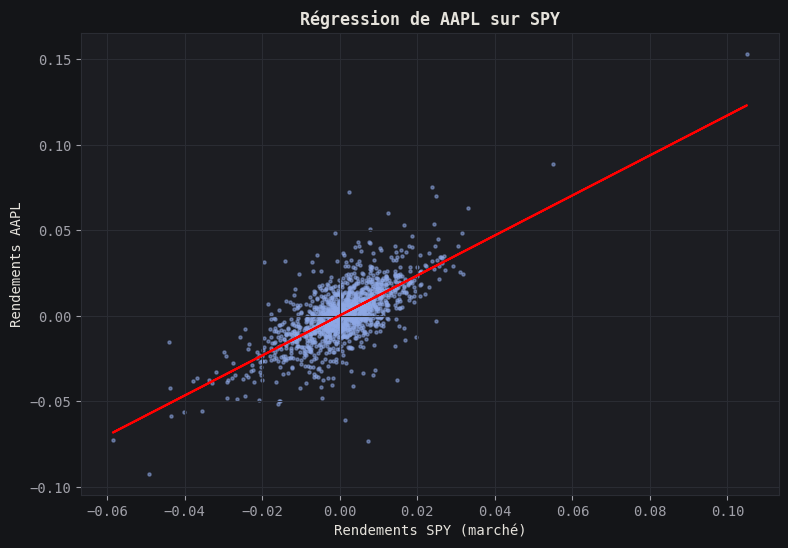

In [18]:
A = "AAPL"   # Actif quelconque
B = "SPY"    # Référence de marché

prix = yf.download([A, B], start="2021-01-01", auto_adjust=True)["Close"]
rendements = prix.pct_change().dropna()

x = rendements[B]
y = rendements[A]

beta, alpha = np.polyfit(x, y, 1)   # pente = bêta, ordonnée = alpha
r2 = np.corrcoef(x, y)[0, 1] ** 2

print(f"Bêta  : {beta:.4f}")
print(f"Alpha : {alpha:.6f}")
print(f"R²    : {r2:.4f}")

plt.scatter(x, y, s=5, alpha=0.5)
plt.plot(x, alpha + beta * x, color="red")
plt.xlabel(f"Rendements {B} (marché)")
plt.ylabel(f"Rendements {A}")
plt.title(f"Régression de {A} sur {B}")
plt.show()

Chaque point du graphique représente une journée de bourse : en abscisse le rendement du S&P 500, en ordonnée celui d'Apple le même jour. La droite rouge est la droite de régression.
- La **pente** est le bêta : $\beta \approx 1.17$. Quand le marché monte (ou baisse) de 1 %, Apple monte (ou baisse) en moyenne d'environ 1.17 %.
- Le **$R^2 \approx 0.50$** indique qu'environ la moitié des variations quotidiennes d'Apple s'expliquent par les mouvements du marché. L'autre moitié est propre à l'entreprise (résultats, nouveaux produits, nouvelles).

## Rendements attendus du marché
Nous avons vu comment calculer ceci dans le dernière séance, on distribue les rendements journaliers pour trouver le rendement moyen par jour et celui par an en multipliant par 252.

E(R_m) quotidien          : 0.05795%


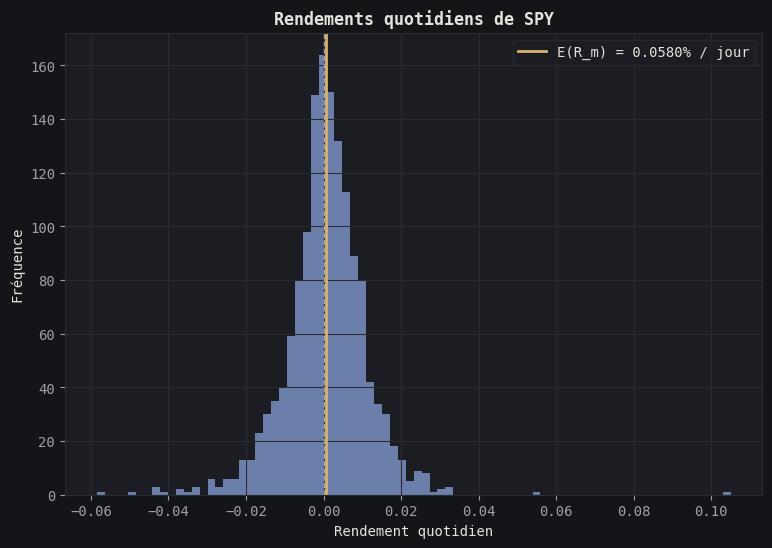

In [19]:
R_m = rendements[B]   # rendements quotidiens du marché (cellule précédente)

E_Rm_jour = R_m.mean()
print(f"E(R_m) quotidien          : {E_Rm_jour:.5%}")

plt.hist(R_m, bins=80, color=ACCENT, alpha=0.7)
plt.axvline(E_Rm_jour, color=GOLD, lw=2, label=f"E(R_m) = {E_Rm_jour:.4%} / jour")
plt.axvline(0, color=MUTED, lw=1, ls="--")
plt.title(f"Rendements quotidiens de {B}")
plt.xlabel("Rendement quotidien")
plt.ylabel("Fréquence")
plt.legend()
plt.show()

La distribution est centrée très près de zéro, et la moyenne quotidienne (environ 0.06 %) est minuscule comparée à la dispersion : une journée typique varie d'environ ±1 %. C'est pour cette raison qu'il faut plusieurs années de données pour estimer le rendement espéré du marché avec une précision raisonnable.

On transforme les rendements moyens journaliers en rendements espérés annuels en multipliant par 252.

In [20]:
E_Rm_annuel = E_Rm_jour * 252                               # moyenne arithmétique annualisée
print(f"E(R_m) annuel (arithm.)   : {E_Rm_annuel:.2%}")

E(R_m) annuel (arithm.)   : 14.60%


14.60 % par an, c'est plus que la moyenne historique à long terme du S&P 500 (environ 10 % par an) : la période 2021-2026 a été particulièrement favorable, malgré la baisse de 2022. La **prime de risque du marché** vaut donc ici
$$\mathbb{E}(R_m)-R_f \approx 14.60\,\% - 3.29\,\% = 11.31\,\%$$
C'est la récompense annuelle supplémentaire obtenue pour avoir investi dans le marché plutôt que dans des bons du Trésor.

Nous avons maintenant tout les paramètres pour calculer le rendement espéré d'un actif. On prends nos données fixes du taux sans risque (3.29%) et des rendements moyens annuels de l'indice de marché, ici le S&P500 (14.61%). On peut maintenant choisir un actif quelquonque pour effectuer la comparaison.

On calcule d'abord le bêta de ce nouveau ticker contre les rendements du S&P500.

[*********************100%***********************]  2 of 2 completed


Bêta  : 1.9950
Alpha : 0.001032
R²    : 0.2450


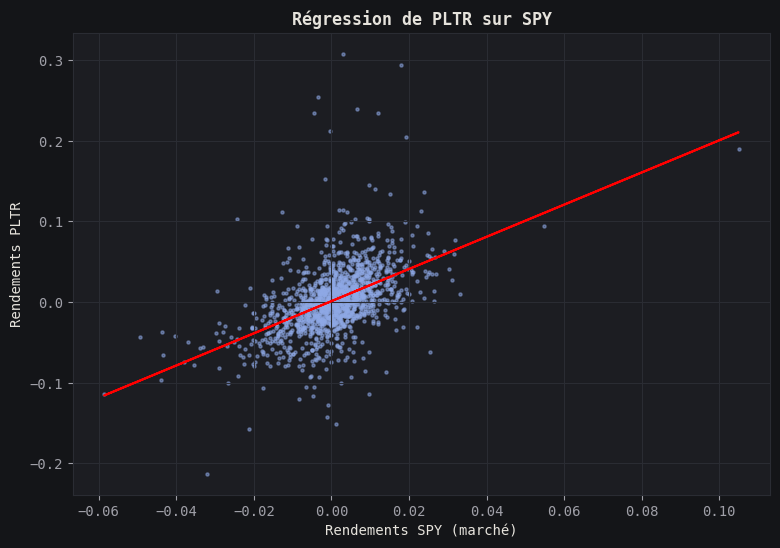

In [23]:
TICKER = "PLTR"   # Actif quelconque
B = "SPY"    # Référence de marché

prix = yf.download([TICKER, B], start="2021-01-01", auto_adjust=True)["Close"]
rendements = prix.pct_change().dropna()

x = rendements[B]
y = rendements[TICKER]

beta, alpha = np.polyfit(x, y, 1)   # pente = bêta, ordonnée = alpha
r2 = np.corrcoef(x, y)[0, 1] ** 2

print(f"Bêta  : {beta:.4f}")
print(f"Alpha : {alpha:.6f}")
print(f"R²    : {r2:.4f}")

plt.scatter(x, y, s=5, alpha=0.5)
plt.plot(x, alpha + beta * x, color="red")
plt.xlabel(f"Rendements {B} (marché)")
plt.ylabel(f"Rendements {TICKER}")
plt.title(f"Régression de {TICKER} sur {B}")
plt.show()

Comparé à Apple, le nuage de points de Palantir est beaucoup plus dispersé :
- $\beta \approx 2.00$ : Palantir est environ deux fois plus sensible que le marché. Une baisse de 1 % du S&P 500 correspond en moyenne à une baisse d'environ 2 % de Palantir.
- $R^2 \approx 0.25$ : seulement un quart de ses variations s'expliquent par le marché. Les trois quarts restants viennent de facteurs propres à l'entreprise (contrats, résultats, engouement des investisseurs).

Il ne nous reste plus qu'à mettre nos paramètres dans l'équation.

In [28]:
E_Ri = rf_moyen + beta * (E_Rm_annuel - rf_moyen)
print(f"E(R) de {TICKER} : {E_Ri:.2%}")

E(R) de PLTR : 25.87%


On peut décomposer ce résultat :
$$\mathbb{E}(R_{PLTR}) \approx \underbrace{3.29\,\%}_{R_f} + \underbrace{2.00 \times 11.31\,\%}_{\beta \,\times\, \text{prime de risque}} \approx 25.9\,\%$$
Le CAPM ne prédit pas que Palantir rapportera 25.87 % l'an prochain. Il dit qu'un investisseur **devrait exiger** ce rendement pour accepter le risque de marché que Palantir lui fait porter. Ce rendement est élevé surtout parce que son bêta double la prime de risque du marché.

## Paramètres de la droite de régression: $α,β$
On à utilisé $β$ comme paramètre dans l'équation CAPM. Cependant, nous pouvons tirer une information clé de sa valeur: la volatilité systématique.

### Le bêta : le risque systématique
Le bêta mesure à quel point un actif **suit** les mouvements du marché.

| $\beta$ | Interprétation | Exemples typiques |
|---|---|---|
| $\beta > 1$ | amplifie les mouvements du marché | technologie (NVDA, PLTR) |
| $\beta = 1$ | bouge comme le marché | SPY |
| $0 < \beta < 1$ | bouge moins que le marché | services publics, consommation de base |
| $\beta < 0$ | bouge à l'inverse du marché | rare (l'or, parfois) |

Attention : le bêta n'est pas la volatilité totale. On peut l'écrire
$$\beta = \rho \cdot \frac{\sigma_i}{\sigma_m}$$
où $\rho$ est la corrélation entre l'actif et le marché. Une action très volatile mais peu corrélée au marché (par exemple une biotech qui attend une décision réglementaire) peut avoir un bêta faible.<br><br>
Le risque total d'un actif se divise en deux parties :
- le **risque systématique**, lié au marché et mesuré par $\beta$ : il touche toutes les actions en même temps et **ne peut pas être éliminé** par la diversification;
- le **risque spécifique** (ou idiosyncratique), propre à l'entreprise : il **disparaît** quand on détient beaucoup d'actions différentes.

Comme le risque spécifique peut être éliminé gratuitement en diversifiant, le marché ne le rémunère pas. C'est pour cette raison que seul $\beta$ apparaît dans le CAPM.<br><br>
Le $R^2$ de la régression donne exactement cette décomposition : c'est la part de la variance de l'actif expliquée par le marché.

In [ ]:
from matplotlib.ticker import PercentFormatter

COMPARAISON = list(dict.fromkeys(["AAPL", TICKER]))

prix_cmp = yf.download(COMPARAISON + [B], start=DEBUT, auto_adjust=True, progress=False)["Close"].dropna()
rend_cmp = prix_cmp.pct_change().dropna()

part_sys = np.array([np.corrcoef(rend_cmp[B], rend_cmp[a])[0, 1] ** 2 for a in COMPARAISON])   # R²
part_spec = 1 - part_sys

plt.figure(figsize=(9, 3.5))
plt.barh(COMPARAISON, part_sys, color=ACCENT, label="Risque systématique (marché)")
plt.barh(COMPARAISON, part_spec, left=part_sys, color="#C97B84", label="Risque spécifique (entreprise)")
for i, (s, p) in enumerate(zip(part_sys, part_spec)):
    plt.text(s / 2, i, f"{s:.0%}", ha="center", va="center", color=BG, fontweight="bold")
    plt.text(s + p / 2, i, f"{p:.0%}", ha="center", va="center", color=BG, fontweight="bold")
plt.xlim(0, 1)
plt.gca().xaxis.set_major_formatter(PercentFormatter(1.0))
plt.title("Décomposition de la variance des rendements")
plt.xlabel("Part de la variance totale")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

Pour Apple, environ la moitié du risque vient du marché; pour Palantir, seulement le quart. Pourtant, c'est Palantir qui a le bêta le plus élevé : son risque spécifique est énorme, mais un investisseur diversifié ne serait pas rémunéré pour celui-ci. Seule la partie bleue compte dans le CAPM.

### L'alpha : le rendement inexpliqué par le marché
L'alpha est l'ordonnée à l'origine de la régression. C'est le rendement moyen de l'actif **un jour où le marché ne bouge pas**, donc la partie de son rendement qui ne vient pas du marché.
- $\alpha > 0$ : l'actif a fait mieux que ce que son bêta laissait prévoir;
- $\alpha = 0$ : l'actif a rapporté exactement ce que son risque de marché justifiait (c'est ce que prédit le CAPM);
- $\alpha < 0$ : l'actif a fait moins bien que prévu.

L'alpha de la régression est quotidien. Pour le comparer aux autres rendements annuels, on le multiplie par 252, comme pour $\mathbb{E}(R_m)$.<br><br>
En gestion de portefeuille, l'alpha mesure la **valeur ajoutée** d'un gestionnaire. Battre le marché en achetant simplement des actions à bêta élevé ne demande aucun talent : c'est seulement prendre plus de risque. Seul un alpha positif indique un rendement obtenu *au-delà* de la récompense pour le risque.

In [ ]:
alpha_annuel = alpha * 252   # alpha de la régression de TICKER sur le marché

print(f"Alpha quotidien de {TICKER}  : {alpha:.4%}")
print(f"Alpha annualisé de {TICKER}  : {alpha_annuel:.2%}")

Un alpha annualisé d'environ 26 % pour Palantir signifie que, depuis 2021, l'action a rapporté beaucoup plus que ce que son lien avec le marché explique. Deux précautions :
- la régression utilise les rendements bruts. L'**alpha de Jensen**, la définition standard, utilise les rendements **en excès** du taux sans risque ($R_i - R_f$ et $R_m - R_f$). Les deux valeurs sont proches, mais pas identiques;
- sur une période de quelques années, un alpha élevé peut refléter la chance autant qu'un véritable avantage.

## La Security Market Line (SML)
La SML est la représentation graphique du CAPM : le rendement attendu d'un actif en fonction de son bêta.
$$\mathbb{E}(R_i)=R_f+\beta_i(\mathbb{E}(R_m)-R_f)$$
Elle part de $R_f$ (un actif à $\beta = 0$ ne porte aucun risque de marché) et passe par le marché ($\beta = 1$). Sa pente est la prime de risque du marché $\mathbb{E}(R_m)-R_f$.<br><br>
Simplement, la droite donne le rendement **« juste »** pour chaque niveau de risque de marché. Selon le CAPM, tout actif devrait se trouver sur cette droite. On compare ici, pour plusieurs actions, le rendement réellement obtenu depuis 2021 et le rendement prédit par le CAPM : l'écart vertical entre les deux est l'alpha.

In [ ]:
from matplotlib.ticker import PercentFormatter

ACTIFS = list(dict.fromkeys(["AAPL", "MSFT", "NVDA", "JPM", "XOM", "JNJ", "PG", TICKER]))

prix_sml = yf.download(ACTIFS + [B], start=DEBUT, auto_adjust=True, progress=False)["Close"].dropna()
rend_sml = prix_sml.pct_change().dropna()

betas = pd.Series({a: np.polyfit(rend_sml[B], rend_sml[a], 1)[0] for a in ACTIFS})
r_hist = rend_sml[ACTIFS].mean() * 252                      # rendement réalisé annuel
r_capm = rf_moyen + betas * (E_Rm_annuel - rf_moyen)        # rendement prédit par le CAPM
alphas = r_hist - r_capm

b = np.linspace(0, betas.max() * 1.15, 100)
plt.plot(b, rf_moyen + b * (E_Rm_annuel - rf_moyen), color=GOLD, lw=2, label="Security Market Line")
plt.scatter(0, rf_moyen, color=GOLD, s=60, zorder=5)
plt.annotate("$R_f$", (0, rf_moyen), xytext=(8, -12), textcoords="offset points", color=GOLD)
plt.scatter(1, E_Rm_annuel, color=INK, marker="D", s=60, zorder=6, label=f"{B} (β = 1)")
for a in ACTIFS:
    couleur = "#7FB8A4" if alphas[a] > 0 else "#C97B84"      # vert : alpha > 0, rose : alpha < 0
    plt.vlines(betas[a], r_capm[a], r_hist[a], color=MUTED, ls=":", lw=1)
    plt.scatter(betas[a], r_hist[a], color=couleur, s=35, zorder=5)
    plt.annotate(a, (betas[a], r_hist[a]), xytext=(5, 4), textcoords="offset points", fontsize=8, color=MUTED)

plt.gca().yaxis.set_major_formatter(PercentFormatter(1.0))
plt.xlabel("Bêta")
plt.ylabel("Rendement annuel")
plt.title("Security Market Line : rendements réalisés vs CAPM")
plt.legend(fontsize=8)
plt.show()

print(pd.DataFrame({"Bêta": betas.round(2),
                    "Réalisé": r_hist.map("{:.1%}".format),
                    "CAPM": r_capm.map("{:.1%}".format),
                    "Alpha": alphas.map("{:.1%}".format)}))

### Comment lire le graphique
- **La droite dorée** est le rendement que chaque action *aurait dû* rapporter selon son bêta.
- **Chaque point** est une action, placée à son bêta et au rendement qu'elle a *réellement* rapporté depuis 2021.
- **Les pointillés** relient les deux : leur longueur est l'alpha.
  - Un point **au-dessus** de la droite (en vert) a rapporté plus que ce que son risque de marché justifiait : $\alpha > 0$.
  - Un point **en dessous** (en rose) a rapporté moins que prévu pour le risque pris : $\alpha < 0$.

Le graphique sépare deux idées qu'on confond souvent : **avoir beaucoup rapporté** et **avoir bien rapporté**. Une action très risquée qui a beaucoup monté peut simplement avoir été payée pour son risque et se retrouver sur la droite. À l'inverse, une action calme au rendement modeste peut se trouver au-dessus de la droite, et donc avoir été une meilleure affaire compte tenu du risque.

## Limites du CAPM
Le CAPM est simple et très utilisé, mais il repose sur des hypothèses fortes :
- tous les investisseurs ont les **mêmes anticipations**, peuvent emprunter et prêter au taux sans risque, et ne s'intéressent qu'à la moyenne et à la variance des rendements;
- le **bêta n'est pas stable** : il change selon la période et la fréquence des données utilisées pour l'estimer;
- le portefeuille de marché théorique contient **tous les actifs** (actions, obligations, immobilier...). Le S&P 500 n'en est qu'une approximation;
- empiriquement, la SML observée est **plus plate** que prévu : les actions à faible bêta rapportent plus que ce que le CAPM prédit, et celles à bêta élevé moins.

Ces limites ont mené aux **modèles multifactoriels**, comme celui de Fama et French, qui ajoutent d'autres sources de risque rémunérées (la taille de l'entreprise, le ratio valeur comptable / valeur de marché) en plus du bêta.

## Conclusion
- Le CAPM relie le rendement espéré d'un actif à son **risque systématique** $\beta$ : $\mathbb{E}(R_i)=R_f+\beta_i(\mathbb{E}(R_m)-R_f)$.
- On l'a estimé avec trois ingrédients : le taux sans risque (bons du Trésor américain), le rendement espéré du marché (S&P 500) et le bêta (pente de la régression).
- Seul le risque de marché est rémunéré : le risque spécifique se diversifie.
- La **SML** compare le rendement réalisé d'un actif au rendement que son risque justifie. L'écart entre les deux est l'**alpha**, la mesure de la performance au-delà du risque pris.